> **My first exploratory notebook, kept with its outputs for reference** (in Spanish, run in Google Colab on 200 images).
> The `retina_dr` package and the README in this repository supersede it. Main differences: the retina is located in each image instead of assuming a centred circle, measurements are per unit of retina, tortuosity is computed per vessel branch, lesion thresholds sit above the noise level and exclude vessels, and the evaluation uses cross-validation on 600 images with the decision threshold chosen inside the training folds (the threshold in "Modelo #3" was chosen on the same test split it was reported on).

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


#**CSV Subset**

In [12]:
import os
import pandas as pd

# ==== CONFIG ====
IMG_DIR = "/content/drive/MyDrive/Retina"  # <- CAMBIAR
CSV_PATH = "/content/drive/MyDrive/Retina/train.csv"         # <- CAMBIAR

IMAGE_COL = "id_code"
LABEL_COL = "diagnosis"



# ==== 1) Leer CSV original ====
df = pd.read_csv(CSV_PATH)
print("Columnas del CSV:", df.columns.tolist())
print(df.head())

# ==== 2) Listar archivos de la carpeta de imágenes ====
valid_exts = (".png", ".jpg", ".jpeg")
all_files = [f for f in os.listdir(IMG_DIR) if f.lower().endswith(valid_exts)]
print(f"Archivos de imagen encontrados en carpeta: {len(all_files)}")

files_set = set(all_files)

# Mapeo de stem -> nombre completo (ej: "000c1434d8d7" -> "000c1434d8d7.png")
stem_to_file = {}
for f in all_files:
    stem, ext = os.path.splitext(f)
    stem_to_file[stem] = f

# ==== 3) Resolver el nombre real de archivo para cada fila del CSV ====
def resolve_filename(name):
    name = str(name)
    # 1) Si coincide exactamente con un archivo (por si el CSV ya trae la extensión)
    if name in files_set:
        return name
    # 2) Si coincide con el "stem" (caso APTOS: CSV tiene "id_code" y archivo es "id_code.png")
    if name in stem_to_file:
        return stem_to_file[name]
    # 3) No se encontró
    return None

df["resolved_name"] = df[IMAGE_COL].apply(resolve_filename)

# ==== 4) Filtrar solo filas con imagen disponible ====
df_exist = df[~df["resolved_name"].isna()].copy()

print(f"Filas originales en CSV: {len(df)}")
print(f"Filas con imagen encontrada: {len(df_exist)}")

# ==== 5) Guardar CSV reducido ====
SUBSET_CSV_PATH = "/content/drive/MyDrive/Retina/train_subset.csv" # <- donde quieras guardarlo
df_exist.to_csv(SUBSET_CSV_PATH, index=False)
print(f"CSV reducido guardado en: {SUBSET_CSV_PATH}")


Columnas del CSV: ['id_code', 'diagnosis']
        id_code  diagnosis
0  000c1434d8d7          2
1  001639a390f0          4
2  0024cdab0c1e          1
3  002c21358ce6          0
4  005b95c28852          0
Archivos de imagen encontrados en carpeta: 600
Filas originales en CSV: 3662
Filas con imagen encontrada: 600
CSV reducido guardado en: /content/drive/MyDrive/Retina/train_subset.csv


# **Preprocesado IMG**

In [13]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==========================
# CONFIGURACIÓN BÁSICA
# ==========================
IMG_DIR = "/content/drive/MyDrive/Retina"  # <- CAMBIAR
CSV_PATH = "/content/drive/MyDrive/Retina/train_subset.csv"         # <- CAMBIAR

IMAGE_COL = "resolved_name"       # nombre de la columna con el nombre de archivo
LABEL_COL = "diagnosis"   # nombre de la columna con la clase (0-4)

TARGET_SIZE = (512, 512)  # tamaño final (ancho, alto)


# ==========================
# UTILIDADES
# ==========================
def load_image_from_row(row):
    """
    Lee una imagen a partir del nombre RESUELTO que viene en el CSV reducido.
    Devuelve la imagen en RGB (uint8).
    """
    img_name = str(row[IMAGE_COL])  # ahora esto ya es algo tipo "000c1434d8d7.png"
    img_path = os.path.join(IMG_DIR, img_name)
    img = cv2.imread(img_path, cv2.IMREAD_COLOR)

    if img is None:
        raise FileNotFoundError(f"No se encontró la imagen: {img_path}")

    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    return img



def crop_to_circle(img):
    """
    Crea una máscara circular centrada y recorta la imagen
    al bounding box del círculo.
    """
    h, w = img.shape[:2]
    center = (w // 2, h // 2)
    radius = int(min(h, w) * 0.48)  # 0.48 para no pegar justo al borde

    mask = np.zeros((h, w), dtype=np.uint8)
    cv2.circle(mask, center, radius, 1, thickness=-1)

    # Aplicar máscara
    masked = cv2.bitwise_and(img, img, mask=(mask * 255))

    # Bounding box del círculo
    ys, xs = np.where(mask == 1)
    y_min, y_max = ys.min(), ys.max()
    x_min, x_max = xs.min(), xs.max()

    cropped = masked[y_min:y_max + 1, x_min:x_max + 1]
    return cropped


def apply_clahe_green_channel(img):
    """
    Aplica CLAHE al canal verde y reconstruye la imagen RGB.
    """
    # Asegurarse que sea uint8
    img = img.astype(np.uint8)

    # Separar canales
    r, g, b = cv2.split(img)

    # CLAHE en canal verde (puedes tunear parámetros)
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    g_eq = clahe.apply(g)

    # Opcional: ajustar también R y B en menor medida (a veces ayuda)
    # r_eq = clahe.apply(r)
    # b_eq = clahe.apply(b)
    # img_eq = cv2.merge([r_eq, g_eq, b_eq])

    img_eq = cv2.merge([r, g_eq, b])
    return img_eq


def preprocess_fundus(img, target_size=TARGET_SIZE):
    """
    Preprocesa una imagen de fondo de ojo:
    - recorte circular
    - resize a target_size
    - CLAHE en canal verde
    - ligera suavización opcional
    """
    # 1) Cropear al círculo de retina
    img_cropped = crop_to_circle(img)

    # 2) Redimensionar
    img_resized = cv2.resize(img_cropped, target_size, interpolation=cv2.INTER_AREA)

    # 3) CLAHE en canal verde
    img_eq = apply_clahe_green_channel(img_resized)

    # 4) Suavizado ligero para ruido fino (opcional)
    img_smooth = cv2.GaussianBlur(img_eq, (3, 3), 0)

    return img_smooth


# ==========================
# VISUALIZACIÓN DE CHEQUEO
# ==========================
def visualize_preprocessing(csv_path=CSV_PATH, n_samples=5, random_state=42):
    """
    Toma n_samples imágenes al azar del CSV y muestra:
    - Original
    - Preprocesada
    con sus diagnósticos.
    """
    df = pd.read_csv(csv_path)

    # Por si hay menos filas que n_samples
    n_samples = min(n_samples, len(df))

    df_sample = df.sample(n=n_samples, random_state=random_state)

    for i, (_, row) in enumerate(df_sample.iterrows(), start=1):
        img = load_image_from_row(row)
        img_pre = preprocess_fundus(img)

        diagnosis = row[LABEL_COL]

        fig, axes = plt.subplots(1, 2, figsize=(8, 4))
        fig.suptitle(f"Ejemplo {i} - DR = {diagnosis}", fontsize=12)

        axes[0].imshow(img)
        axes[0].set_title("Original")
        axes[0].axis("off")

        axes[1].imshow(img_pre)
        axes[1].set_title("Preprocesada")
        axes[1].axis("off")

        plt.tight_layout()
        plt.show()


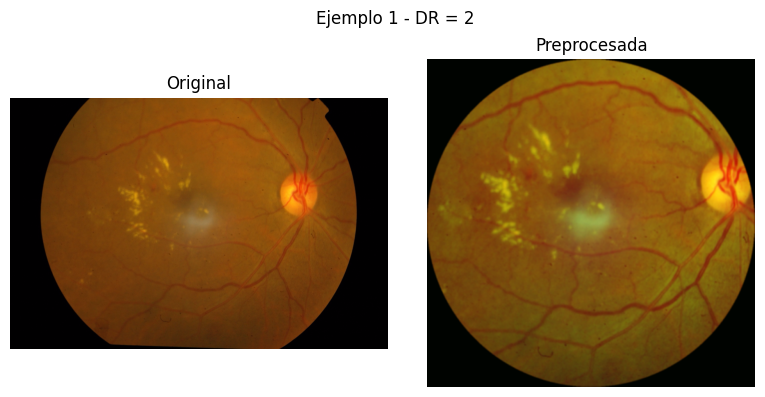

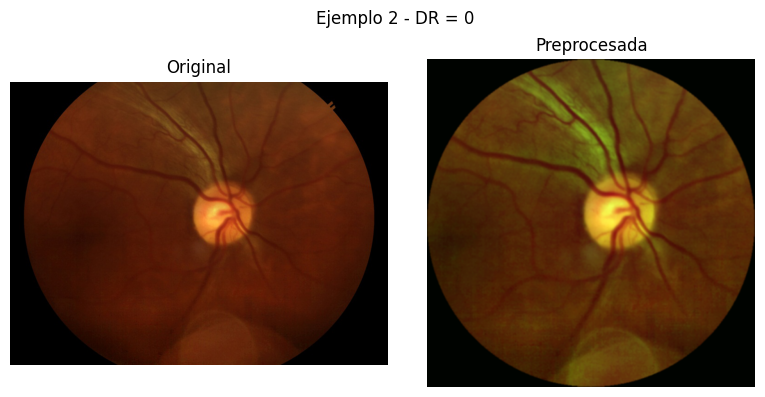

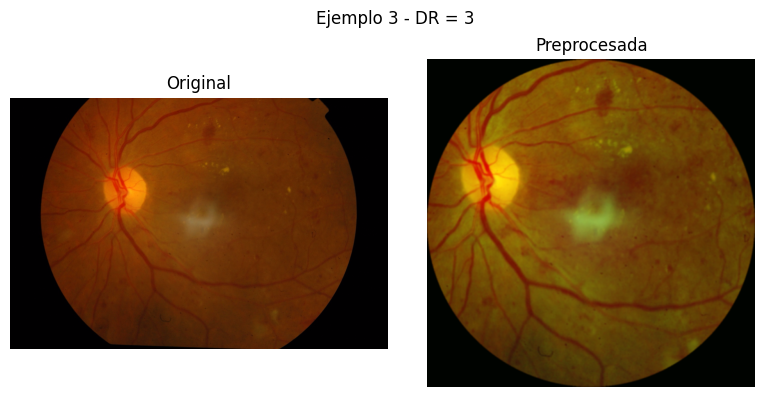

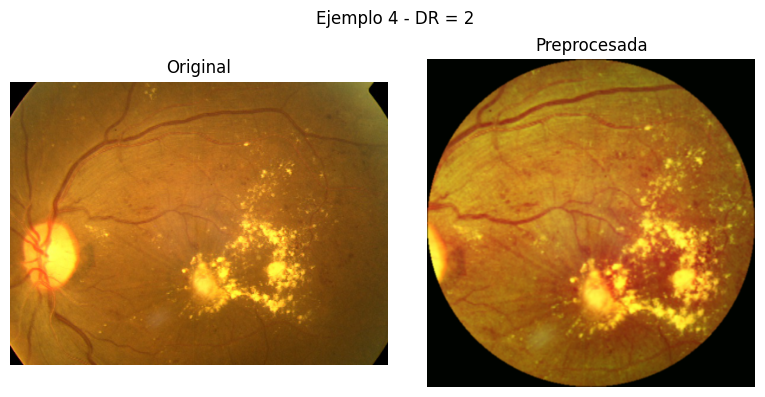

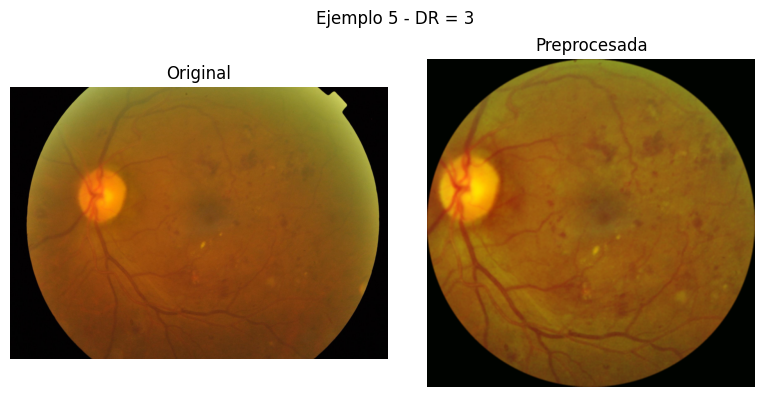

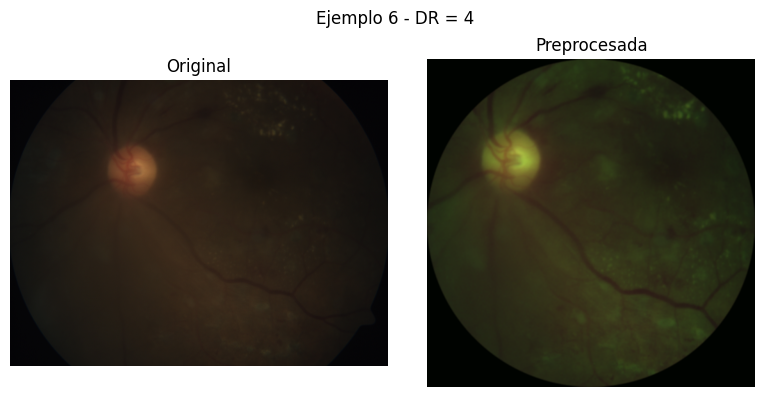

In [14]:
visualize_preprocessing(n_samples=6)

# **FCUnet y generación máscaras**

In [ ]:
!git clone https://github.com/JavierGurrola/FCU-Net.git
%cd FCU-Net

# Dependencias aproximadas del README (podés relajar las versiones si hace falta)
!pip install torch torchvision scikit-image tqdm ptflops pyyaml

Cloning into 'FCU-Net'...
remote: Enumerating objects: 74, done.
remote: Counting objects: 100% (5/5), done.
remote: Compressing objects: 100% (5/5), done.
remote: Total 74 (delta 2), reused 0 (delta 0), pack-reused 69 (from 1)
Receiving objects: 100% (74/74), 6.84 MiB | 11.94 MiB/s, done.
Resolving deltas: 100% (15/15), done.
/content/FCU-Net


In [ ]:
import torch
import sys
from pathlib import Path
import yaml
import inspect

# ====== CONFIG BÁSICA ======
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
MODEL_PATH = "pretrained/model_drive.pth"

# ====== CARGAR CONFIG ======
config_path = "src/config.yaml"
with open(config_path, "r") as f:
    config = yaml.safe_load(f)

print('config["model"]:', config["model"])

# ====== IMPORTAR MODELO ======
SRC_DIR = Path.cwd() / "src"
sys.path.append(str(SRC_DIR))

from model import FCUnet   # clase detectada con inspect

print("Firma de FCUnet:", inspect.signature(FCUnet))

# ====== INICIALIZAR MODELO CON KWARGS DE CONFIG ======
model = FCUnet(**config["model"]).to(DEVICE)

# ====== CARGAR PESOS ======
state = torch.load(MODEL_PATH, map_location=DEVICE)
print("Tipo de checkpoint:", type(state))

if isinstance(state, dict):
    print("Cantidad de claves en checkpoint:", len(state))

    # ¿Alguna clave empieza con 'module.'?
    any_module_prefix = any(k.startswith("module.") for k in state.keys())
    if any_module_prefix:
        print("Detectado prefijo 'module.' en las claves del state_dict. Limpiando...")
        clean_state = {}
        for k, v in state.items():
            new_key = k.replace("module.", "", 1)  # quitar 'module.' una vez
            clean_state[new_key] = v
        state_to_load = clean_state
    else:
        state_to_load = state

    # Cargar en el modelo (strict=False por si quedan detalles menores)
    missing, unexpected = model.load_state_dict(state_to_load, strict=False)
    print("Missing keys al cargar:", missing)
    print("Unexpected keys al cargar:", unexpected)

else:
    # caso raro: guardaron el modelo entero
    print("Checkpoint no es un dict; se asume que es el modelo completo.")
    model = state.to(DEVICE)

model.eval()
print("✅ FCUnet cargado con pesos DRIVE y listo para inferencia.")


config["model"]: {'base filters': 16, 'dropout rate': 0.3}
Firma de FCUnet: (**kwargs)
Tipo de checkpoint: <class 'collections.OrderedDict'>
Cantidad de claves en checkpoint: 125
Detectado prefijo 'module.' en las claves del state_dict. Limpiando...
Missing keys al cargar: []
Unexpected keys al cargar: []
✅ FCUnet cargado con pesos DRIVE y listo para inferencia.


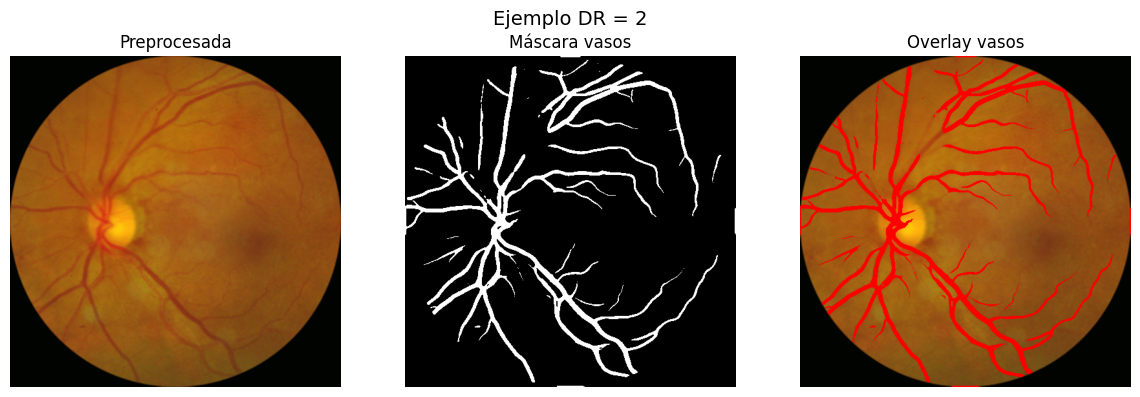

In [ ]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

import numpy as np
import cv2
import matplotlib.pyplot as plt

def segment_vessels_fcu(img_rgb, use_preprocess=True):
    """
    Segmenta la vasculatura en una imagen de fondo de ojo usando FCUnet.

    Parámetros
    ----------
    img_rgb : np.ndarray
        Imagen RGB uint8 original (H, W, 3).
    use_preprocess : bool
        Si True, aplica preprocess_fundus antes de segmentar.

    Devuelve
    --------
    vessel_mask : np.ndarray
        Máscara binaria de vasos (0/1) de tamaño HxW.
    prob_map : np.ndarray
        Mapa de probabilidad (float32 0..1) de tamaño HxW.
    img_proc : np.ndarray
        Imagen RGB preprocesada que se usó como entrada al modelo.
    """
    model.eval()

    # 1) Preprocesamiento
    if use_preprocess:
        img_proc = preprocess_fundus(img_rgb)
    else:
        img_proc = img_rgb.copy()

    # Asegurarnos de que sea RGB uint8
    img_proc = img_proc.astype(np.uint8)

    # 2) Normalizar a [0, 1] en los 3 canales
    img_norm = img_proc.astype(np.float32) / 255.0   # (H, W, 3)

    # 3) A tensor [1, 3, H, W]
    tensor = torch.from_numpy(img_norm).permute(2, 0, 1).unsqueeze(0).to(DEVICE)

    with torch.no_grad():
        logits = model(tensor)           # [1, 1, H, W]
        prob = torch.sigmoid(logits)

    # 4) A numpy
    prob_map = prob[0, 0].cpu().numpy()
    vessel_mask = (prob_map > 0.5).astype(np.uint8)   # umbral ajustable

    return vessel_mask, prob_map, img_proc





df = pd.read_csv(CSV_PATH)

# Tomamos una fila al azar
row = df.sample(1, random_state=0).iloc[0]
diagnosis = row["diagnosis"]   # cambia si tu columna se llama distinto

# Cargar imagen original
img = load_image_from_row(row)   # debe devolver RGB uint8

# Segmentar vasos
vessel_mask, prob_map, img_pre = segment_vessels_fcu(img, use_preprocess=True)

# Crear overlay de vasos en rojo
overlay = img_pre.copy()
overlay[vessel_mask == 1] = [255, 0, 0]

# Visualizar
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
fig.suptitle(f"Ejemplo DR = {diagnosis}", fontsize=14)

axes[0].imshow(img_pre)
axes[0].set_title("Preprocesada")
axes[0].axis("off")

axes[1].imshow(vessel_mask, cmap="gray")
axes[1].set_title("Máscara vasos")
axes[1].axis("off")

axes[2].imshow(overlay)
axes[2].set_title("Overlay vasos")
axes[2].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
def masks_viewer(csv_path, n_samples=4, random_state=42):
    """
    Visualiza ejemplos completos del pipeline:
      - Imagen original (con diagnosis en el título)
      - Imagen preprocesada + máscara de vasos
      - Imagen preprocesada + overlay de vasos en rojo

    Parámetros
    ----------
    csv_path : str
        Ruta al CSV reducido (con 'resolved_name' y 'diagnosis').
    n_samples : int
        Cantidad de ejemplos a mostrar.
    random_state : int
        Semilla para la selección aleatoria.
    """
    df = pd.read_csv(csv_path)
    n_samples = min(n_samples, len(df))
    df_sample = df.sample(n=n_samples, random_state=random_state)

    for i, (_, row) in enumerate(df_sample.iterrows(), start=1):
        diagnosis = row["diagnosis"]
        img = load_image_from_row(row)

        # Segmentar vasos
        vessel_mask, prob_map, img_pre = segment_vessels_fcu(img, use_preprocess=True)

        # Overlay
        overlay = img_pre.copy()
        overlay[vessel_mask == 1] = [255, 0, 0]

        # Plot
        fig, axes = plt.subplots(1, 3, figsize=(14, 5))
        fig.suptitle(f"Ejemplo {i}", fontsize=14)

        # Imagen original con diagnóstico
        axes[0].imshow(img)
        axes[0].set_title(f"Original (DR={diagnosis})")
        axes[0].axis("off")

        # Máscara + preprocesada
        axes[1].imshow(img_pre)
        axes[1].imshow(vessel_mask, cmap="Reds", alpha=0.5)
        axes[1].set_title("Preprocesada + Máscara")
        axes[1].axis("off")

        # Overlay final
        axes[2].imshow(overlay)
        axes[2].set_title("Overlay vasos")
        axes[2].axis("off")

        plt.tight_layout()
        plt.show()


In [ ]:
masks_viewer(CSV_PATH, n_samples= 5)

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
import os
import numpy as np
import cv2
import pandas as pd

def generate_all_vessel_masks(
    csv_path,
    output_dir,
    use_preprocess=True,
    overwrite=False,
    log_every=20
):
    """
    Genera máscaras de vasculatura para todas las imágenes listadas en csv_path
    usando el modelo FCUnet y las guarda como PNG en output_dir.

    Parámetros
    ----------
    csv_path : str
        Ruta al CSV reducido (ej: fundus_subset.csv) que tiene al menos
        las columnas 'resolved_name' y 'diagnosis' (o la que uses).
    output_dir : str
        Carpeta donde se guardarán las máscaras generadas.
    use_preprocess : bool
        Si True, aplica preprocess_fundus dentro de segment_vessels_fcu.
    overwrite : bool
        Si False, no vuelve a generar máscaras que ya existan.
    log_every : int
        Imprime un mensaje cada 'log_every' imágenes procesadas.
    """
    os.makedirs(output_dir, exist_ok=True)

    df = pd.read_csv(csv_path)
    n = len(df)
    print(f"Se encontraron {n} filas en el CSV.")

    for i, (_, row) in enumerate(df.iterrows(), start=1):
        img_name = str(row["resolved_name"])  # ajusta si tu col se llama distinto
        base_name, _ = os.path.splitext(img_name)
        mask_filename = base_name + "_vessels.png"
        out_path = os.path.join(output_dir, mask_filename)

        if (not overwrite) and os.path.exists(out_path):
            if i % log_every == 0:
                print(f"[{i}/{n}] Ya existía, se salta: {mask_filename}")
            continue

        try:
            # Cargar imagen original
            img = load_image_from_row(row)  # RGB uint8

            # Segmentar vasos
            vessel_mask, _, _ = segment_vessels_fcu(img, use_preprocess=use_preprocess)

            # Convertir a uint8 0–255
            mask_uint8 = (vessel_mask * 255).astype(np.uint8)

            # Guardar
            cv2.imwrite(out_path, mask_uint8)

            if i % log_every == 0:
                print(f"[{i}/{n}] Máscara guardada: {mask_filename}")

        except Exception as e:
            print(f"[{i}/{n}] Error en {img_name}: {e}")

    print("✅ Generación de máscaras finalizada.")

In [ ]:
OUTPUT_DIR = "/content/drive/MyDrive/Retina/vessel_masks"

generate_all_vessel_masks(
    csv_path=CSV_PATH,
    output_dir=OUTPUT_DIR,
    use_preprocess=True,
    overwrite=False,
    log_every=20
)


Se encontraron 200 filas en el CSV.
[20/200] Ya existía, se salta: f233638e0e90_vessels.png
[40/200] Ya existía, se salta: f3cd489acbee_vessels.png
[60/200] Ya existía, se salta: f5650eb52640_vessels.png
[80/200] Ya existía, se salta: f68690db78d3_vessels.png
[100/200] Ya existía, se salta: f80118bbda18_vessels.png
[120/200] Ya existía, se salta: f9d52509c571_vessels.png
[140/200] Ya existía, se salta: fb88783de055_vessels.png
[160/200] Ya existía, se salta: fd079d2e93a2_vessels.png
[180/200] Ya existía, se salta: febfb20dc311_vessels.png
[200/200] Ya existía, se salta: ffec9a18a3ce_vessels.png
✅ Generación de máscaras finalizada.


# **Extracción de variables vasculares #1**

In [24]:
import numpy as np
import cv2
from skimage.morphology import skeletonize
from skimage.measure import label, regionprops
from scipy.ndimage import convolve
from skimage.util import invert
import pandas as pd


# ---------------------------
# A) Esqueletización
# ---------------------------
def get_skeleton(mask):
    """
    mask: binary mask (0/1)
    returns skeleton as binary mask
    """
    mask_bool = mask.astype(bool)
    skel = skeletonize(mask_bool)
    return skel.astype(np.uint8)


# ---------------------------
# B) Contar endpoints y bifurcaciones
# ---------------------------
# Kernel para contar vecinos
kernel = np.array([[1,1,1],
                   [1,10,1],
                   [1,1,1]])

def get_node_counts(skel):
    """
    Devuelve cantidad de endpoints y bifurcaciones en el skeleton.
    """

    # Convolución: el centro vale 10, vecinos valen 1
    conv = convolve(skel.astype(np.uint8), kernel, mode='constant')

    # En un skeleton:
    # endpoint = 11 (10 + 1 vecino)
    # bifurcación típica = 13, 14, 15... (≥3 vecinos)
    endpoints = np.sum(conv == 11)
    bifurcations = np.sum(conv >= 13)

    return endpoints, bifurcations


# ---------------------------
# C) Longitud del skeleton
# ---------------------------
def get_skeleton_length(skel):
    """
    Longitud total del skeleton en píxeles.
    """
    return np.sum(skel == 1)


# ---------------------------
# D) Dimensión fractal (box-counting)
# ---------------------------
def fractal_dimension(mask):
    """
    Box-counting fractal dimension.
    """

    Z = mask > 0
    N = min(Z.shape)

    sizes = 2**np.arange(int(np.log2(N)), 1, -1)
    counts = []

    for size in sizes:
        # dividir en bloques
        S = (Z.reshape(Z.shape[0]//size, size,
                       Z.shape[1]//size, size)
               .max(axis=(1,3)))
        counts.append(np.sum(S))

    # ajuste log-log
    logs = np.log(sizes)
    log_counts = np.log(counts)
    coeffs = np.polyfit(logs, log_counts, 1)

    return -coeffs[0]   # la pendiente negativa es la dimensión fractal

In [25]:
from skimage.graph import route_through_array
from scipy.spatial.distance import euclidean

def extract_branch_tortuosity(skel):
    """
    Extrae todas las ramas conectadas del esqueleto y calcula
    su tortuosidad.
    """
    # Etiquetar componentes del skeleton
    labeled = label(skel, connectivity=2)
    props = regionprops(labeled)

    tortuosities = []
    lengths = []

    for region in props:
        coords = region.coords

        # Si el segmento es muy corto, ignorar
        if len(coords) < 5:
            continue

        # tomamos dos puntos extremos del bounding box
        y_min, x_min = region.bbox[0], region.bbox[1]
        y_max, x_max = region.bbox[2]-1, region.bbox[3]-1

        p1 = (y_min, x_min)
        p2 = (y_max, x_max)

        # ruta más corta siguiendo skeleton (cost = inverted skeleton)
        cost = invert(skel.astype(np.uint8))
        path, path_cost = route_through_array(
            cost, p1, p2, fully_connected=True
        )

        path = np.array(path)
        L_real = len(path)
        L_euc = euclidean(p1, p2)

        if L_euc > 0:
            tort = L_real / L_euc
            tortuosities.append(tort)
            lengths.append(L_real)

    if len(tortuosities) == 0:
        return {
            "tortuosity_mean": 0,
            "tortuosity_max": 0,
            "segments": 0
        }

    return {
        "tortuosity_mean": float(np.mean(tortuosities)),
        "tortuosity_max": float(np.max(tortuosities)),
        "segments": len(tortuosities)
    }

In [26]:
def extract_vascular_features(mask):
    """
    mask: máscara binaria (0/1) de vasos segmentados.

    Devuelve un diccionario de métricas morfométricas.
    """

    features = {}

    # 1) Densidad vascular (píxeles positivos)
    vascular_area = np.sum(mask == 1)
    features["vascular_area"] = int(vascular_area)

    # 2) Skeleton
    skel = get_skeleton(mask)
    skel_len = get_skeleton_length(skel)
    features["skeleton_length"] = int(skel_len)

    # 3) Endpoints y bifurcaciones
    endpoints, bifurcations = get_node_counts(skel)
    features["endpoints"] = int(endpoints)
    features["bifurcations"] = int(bifurcations)

    # 4) Relación endpoints/bifurcaciones
    if bifurcations > 0:
        features["endpoint_bif_ratio"] = endpoints / bifurcations
    else:
        features["endpoint_bif_ratio"] = np.nan

    # 5) Dimensión fractal
    features["fractal_dimension"] = float(fractal_dimension(mask))

    # 6) Tortuosidad
    tort = extract_branch_tortuosity(skel)
    features.update(tort)

    return features

In [27]:
def extract_features_from_all_masks(csv_path, masks_dir):
    """
    Recorre el CSV reducido, carga cada máscara _vessels.png,
    calcula las métricas morfométricas y devuelve un DataFrame
    con diagnóstico incluido.

    Requisitos:
        - masks_dir contiene: nombre_vessels.png
        - csv_path contiene: resolved_name, diagnosis
    """

    df = pd.read_csv(csv_path)
    rows = []

    for _, row in df.iterrows():
        img_name = row["resolved_name"]
        diag = row["diagnosis"]
        base, _ = os.path.splitext(img_name)

        mask_path = os.path.join(masks_dir, base + "_vessels.png")
        mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

        if mask is None:
            print("No se encontró máscara:", mask_path)
            continue

        mask_bin = (mask > 127).astype(np.uint8)

        feats = extract_vascular_features(mask_bin)
        feats["image"] = img_name
        feats["diagnosis"] = diag

        rows.append(feats)

    return pd.DataFrame(rows)

In [28]:
features_df = extract_features_from_all_masks(
    csv_path=CSV_PATH,
    masks_dir="/content/drive/MyDrive/Retina/vessel_masks"
)

features_df.head()


No se encontró máscara: /content/drive/MyDrive/Retina/vessel_masks/d3be5346684b_vessels.png
No se encontró máscara: /content/drive/MyDrive/Retina/vessel_masks/d3d578fe433f_vessels.png
No se encontró máscara: /content/drive/MyDrive/Retina/vessel_masks/d3de0d313d61_vessels.png
No se encontró máscara: /content/drive/MyDrive/Retina/vessel_masks/d3dfd0a2dee6_vessels.png
No se encontró máscara: /content/drive/MyDrive/Retina/vessel_masks/d567a1a22d33_vessels.png
No se encontró máscara: /content/drive/MyDrive/Retina/vessel_masks/d56d32a1d62d_vessels.png
No se encontró máscara: /content/drive/MyDrive/Retina/vessel_masks/d57d1be1bbd1_vessels.png
No se encontró máscara: /content/drive/MyDrive/Retina/vessel_masks/d5a39339ff3d_vessels.png
No se encontró máscara: /content/drive/MyDrive/Retina/vessel_masks/d5ad3362424c_vessels.png
No se encontró máscara: /content/drive/MyDrive/Retina/vessel_masks/d5b4705ac2ee_vessels.png
No se encontró máscara: /content/drive/MyDrive/Retina/vessel_masks/d5c63a8d9e94_

,vascular_area,skeleton_length,endpoints,bifurcations,endpoint_bif_ratio,fractal_dimension,tortuosity_mean,tortuosity_max,segments,image,diagnosis
0,29674,6060,117,360,0.325000,1.669801,0.940439,1.142857,16,f002ce614c59.png,0
1,23472,5190,130,190,0.684211,1.633860,1.023301,1.250000,22,f00ce9b9d6f4.png,0
2,12840,2707,68,65,1.046154,1.476767,0.936775,1.200000,21,f025f33b2c9b.png,4
3,31662,7281,143,377,0.379310,1.705540,1.009680,1.250000,30,f02babb3a023.png,0
4,21956,5216,121,233,0.519313,1.623123,0.977175,1.250000,21,f03d3c4ce7fb.png,4


In [29]:
# Guardar el dataframe como CSV
output_csv = "vascular_features.csv"
features_df.to_csv(output_csv, index=False)

# Descargar a tu computadora
from google.colab import files
files.download(output_csv)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# **Modelo #1**

In [30]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix
from xgboost import XGBClassifier


# ============================
# 1) Cargar tu CSV con features
# ============================
df = features_df.copy()   # o pd.read_csv("vascular_features.csv")

# ----------------------------
# 2) Limpieza básica
# ----------------------------
# Reemplazar NaNs en razones
df["endpoint_bif_ratio"] = df["endpoint_bif_ratio"].fillna(0)

# Asegurar tipo entero para diagnosis
df["diagnosis"] = df["diagnosis"].astype(int)

# ----------------------------
# 3) Separar features y label
# ----------------------------
feature_cols = [
    "vascular_area",
    "skeleton_length",
    "endpoints",
    "bifurcations",
    "endpoint_bif_ratio",
    "fractal_dimension",
    "tortuosity_mean",
    "tortuosity_max",
    "segments"
]

X = df[feature_cols].values
y = df["diagnosis"].values

# ----------------------------
# 4) Train-test split
# ----------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

# ----------------------------
# 5) Normalización
# ----------------------------
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


# ============================
# 6) Entrenar modelo XGBoost
# ============================
model = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.9,
    colsample_bytree=0.9,
    objective="multi:softprob",
    num_class=5,           # 0–4
    eval_metric="mlogloss"
)

model.fit(X_train_scaled, y_train)

# ============================
# 7) Evaluación
# ============================
y_pred = model.predict(X_test_scaled)

print("===== CLASSIFICATION REPORT =====")
print(classification_report(y_test, y_pred))

print("===== CONFUSION MATRIX =====")
print(confusion_matrix(y_test, y_pred))


===== CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

           0       0.76      0.81      0.79        27
           1       0.00      0.00      0.00         4
           2       0.64      0.64      0.64        11
           3       0.00      0.00      0.00         3
           4       0.25      0.20      0.22         5

    accuracy                           0.60        50
   macro avg       0.33      0.33      0.33        50
weighted avg       0.57      0.60      0.59        50

===== CONFUSION MATRIX =====
[[22  2  1  1  1]
 [ 1  0  2  0  1]
 [ 2  2  7  0  0]
 [ 2  0  0  0  1]
 [ 2  0  1  1  1]]


In [31]:
df['diagnosis'].value_counts()

,count
diagnosis,
0,110
2,45
4,18
1,17
3,10


In [32]:
import pandas as pd
import numpy as np

!pip install mord

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix, cohen_kappa_score, mean_absolute_error

import mord  # librería de ordinal regression


# ============================
# 1) Tomamos el dataframe
# ============================
df = features_df.copy()   # o pd.read_csv("vascular_features.csv")

# Limpieza básica
df["endpoint_bif_ratio"] = df["endpoint_bif_ratio"].fillna(0)
df["diagnosis"] = df["diagnosis"].astype(int)

feature_cols = [
    "vascular_area",
    "skeleton_length",
    "endpoints",
    "bifurcations",
    "endpoint_bif_ratio",
    "fractal_dimension",
    "tortuosity_mean",
    "tortuosity_max",
    "segments"
]

X = df[feature_cols].values
y = df["diagnosis"].values  # 0–4 ordenados


# ============================
# 2) Train-test split estratificado
# ============================
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)


# ============================
# 3) Pipeline: escalado + modelo ordinal
# ============================
ordinal_model = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", mord.LogisticAT(alpha=1.0))  # alpha es regularización L2
])

ordinal_model.fit(X_train, y_train)

y_pred = ordinal_model.predict(X_test)

# ============================
# 4) Métricas
# ============================
print("===== CLASSIFICATION REPORT (ORDINAL) =====")
print(classification_report(y_test, y_pred))

print("===== CONFUSION MATRIX (ORDINAL) =====")
print(confusion_matrix(y_test, y_pred))

# Métrica típica en DR: Quadratic Weighted Kappa
qwk = cohen_kappa_score(y_test, y_pred, weights="quadratic")
print(f"Quadratic Weighted Kappa: {qwk:.3f}")

# Error absoluto medio (respetando orden)
mae = mean_absolute_error(y_test, y_pred)
print(f"Mean Absolute Error (|y_true - y_pred|): {mae:.3f}")


===== CLASSIFICATION REPORT (ORDINAL) =====
              precision    recall  f1-score   support

           0       0.79      0.70      0.75        27
           1       0.17      0.25      0.20         4
           2       0.25      0.45      0.32        11
           3       0.00      0.00      0.00         3
           4       0.00      0.00      0.00         5

    accuracy                           0.50        50
   macro avg       0.24      0.28      0.25        50
weighted avg       0.50      0.50      0.49        50

===== CONFUSION MATRIX (ORDINAL) =====
[[19  2  6  0  0]
 [ 1  1  2  0  0]
 [ 4  2  5  0  0]
 [ 0  0  3  0  0]
 [ 0  1  4  0  0]]
Quadratic Weighted Kappa: 0.464
Mean Absolute Error (|y_true - y_pred|): 0.820


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Proporción de DR (1) en dataset: 0.45
===== CLASSIFICATION REPORT (BINARIO 0 vs DR) =====
              precision    recall  f1-score   support

           0       0.73      0.79      0.76        28
           1       0.70      0.64      0.67        22

    accuracy                           0.72        50
   macro avg       0.72      0.71      0.71        50
weighted avg       0.72      0.72      0.72        50

===== CONFUSION MATRIX (BINARIO) =====
[[22  6]
 [ 8 14]]
ROC-AUC: 0.804


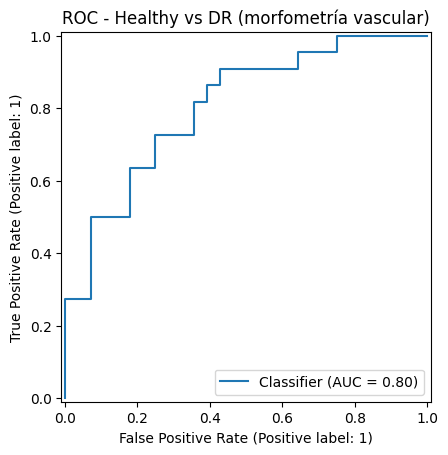

In [33]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    RocCurveDisplay
)
from xgboost import XGBClassifier
import matplotlib.pyplot as plt


# ============================
# 1) Partimos de features_df
# ============================
df_bin = features_df.copy()

# Limpieza básica
df_bin["endpoint_bif_ratio"] = df_bin["endpoint_bif_ratio"].fillna(0)
df_bin["diagnosis"] = df_bin["diagnosis"].astype(int)

feature_cols = [
    "vascular_area",
    "skeleton_length",
    "endpoints",
    "bifurcations",
    "endpoint_bif_ratio",
    "fractal_dimension",
    "tortuosity_mean",
    "tortuosity_max",
    "segments"
]

X = df_bin[feature_cols].values

# ----------------------------
# 2) Construir label binaria
# ----------------------------
# 0 = sano
# 1 = cualquier grado de DR (1,2,3,4)
y_bin = (df_bin["diagnosis"] > 0).astype(int).values

print("Proporción de DR (1) en dataset:", y_bin.mean())


# ============================
# 3) Train-test split
# ============================
X_train, X_test, y_train, y_test = train_test_split(
    X, y_bin,
    test_size=0.25,
    random_state=42,
    stratify=y_bin
)

# ============================
# 4) Pipeline: escalado + XGBoost
# ============================
pipeline_bin = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", XGBClassifier(
        n_estimators=300,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.9,
        colsample_bytree=0.9,
        objective="binary:logistic",
        eval_metric="logloss",
        scale_pos_weight=(y_train == 0).sum() / max((y_train == 1).sum(), 1)  # balance clases
    ))
])

pipeline_bin.fit(X_train, y_train)

# ============================
# 5) Evaluación
# ============================
y_proba = pipeline_bin.predict_proba(X_test)[:, 1]
y_pred = (y_proba >= 0.5).astype(int)

print("===== CLASSIFICATION REPORT (BINARIO 0 vs DR) =====")
print(classification_report(y_test, y_pred))

print("===== CONFUSION MATRIX (BINARIO) =====")
print(confusion_matrix(y_test, y_pred))

roc_auc = roc_auc_score(y_test, y_proba)
print(f"ROC-AUC: {roc_auc:.3f}")

# Curva ROC
RocCurveDisplay.from_predictions(y_test, y_proba)
plt.title("ROC - Healthy vs DR (morfometría vascular)")
plt.show()


#**Extracción de variables vasculares #2**

In [34]:
import cv2
import numpy as np
from skimage.morphology import remove_small_objects

def detect_bright_lesions(img_pre,
                          min_size=10,
                          max_size=500):
    """
    Detecta regiones brillantes (posibles exudados) en una imagen preprocesada.

    img_pre: RGB uint8 (ya preprocesada, 512x512)
    min_size, max_size: tamaño mínimo/máximo (en píxeles) de las regiones a considerar.
    """

    # 1) Pasar a LAB y tomar canal de luminancia
    lab = cv2.cvtColor(img_pre, cv2.COLOR_RGB2LAB)
    L, A, B = cv2.split(lab)

    # 2) Top-hat para resaltar spots brillantes
    se = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15))
    tophat = cv2.morphologyEx(L, cv2.MORPH_TOPHAT, se)

    # 3) Umbral adaptativo
    _, th = cv2.threshold(tophat, 0, 255, cv2.THRESH_OTSU)

    # 4) Limpiar con apertura
    th = cv2.morphologyEx(th, cv2.MORPH_OPEN,
                          cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3)))

    # 5) Remover objetos muy pequeños / muy grandes
    mask = th > 0
    # skimage trabaja con bool
    mask = remove_small_objects(mask, min_size=min_size)

    # eliminar objetos enormes (no deberían ser exudados)
    labeled = cv2.connectedComponentsWithStats(mask.astype(np.uint8), connectivity=8)
    labels = labeled[1]
    stats = labeled[2]

    final_mask = np.zeros_like(mask, dtype=bool)
    for i, st in enumerate(stats):
        if i == 0:  # fondo
            continue
        area = st[cv2.CC_STAT_AREA]
        if min_size <= area <= max_size:
            final_mask[labels == i] = True

    return final_mask.astype(np.uint8)  # 0/1


from skimage.morphology import opening

def detect_dark_lesions(img_pre,
                        min_size=5,
                        max_size=300):
    """
    Detecta lesiones oscuras pequeñas (microaneurismas/hemorragias) en una imagen preprocesada.
    """

    # 1) Canal verde + CLAHE ligero
    g = img_pre[:, :, 1]
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    g_eq = clahe.apply(g)

    # 2) Invertir para que las zonas oscuras se vuelvan brillantes
    g_inv = 255 - g_eq

    # 3) Top-hat sobre g_inv
    se = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (9, 9))
    tophat = cv2.morphologyEx(g_inv, cv2.MORPH_TOPHAT, se)

    # 4) Umbral (Otsu)
    _, th = cv2.threshold(tophat, 0, 255, cv2.THRESH_OTSU)

    # 5) Apertura para sacar ruido fino
    th = cv2.morphologyEx(th, cv2.MORPH_OPEN,
                          cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3)))

    mask = th > 0

    # 6) Filtrar por tamaño
    labeled = cv2.connectedComponentsWithStats(mask.astype(np.uint8), connectivity=8)
    labels = labeled[1]
    stats = labeled[2]

    final_mask = np.zeros_like(mask, dtype=bool)
    for i, st in enumerate(stats):
        if i == 0:
            continue
        area = st[cv2.CC_STAT_AREA]
        if min_size <= area <= max_size:
            final_mask[labels == i] = True

    return final_mask.astype(np.uint8)



def lesion_features_from_masks(mask_bright, mask_dark):
    """
    Recibe dos máscaras 0/1 y devuelve features numéricas.
    """

    feats = {}

    # BRIGHT
    bright_area = int(mask_bright.sum())
    labeled_b, _, stats_b, _ = cv2.connectedComponentsWithStats(mask_bright, connectivity=8)
    bright_count = max(labeled_b - 1, 0)  # restar fondo

    areas_b = [st[cv2.CC_STAT_AREA] for i, st in enumerate(stats_b) if i != 0]
    bright_mean_area = float(np.mean(areas_b)) if len(areas_b) > 0 else 0.0

    feats["bright_lesion_area"] = bright_area
    feats["bright_lesion_count"] = bright_count
    feats["bright_lesion_mean_area"] = bright_mean_area

    # DARK
    dark_area = int(mask_dark.sum())
    labeled_d, _, stats_d, _ = cv2.connectedComponentsWithStats(mask_dark, connectivity=8)
    dark_count = max(labeled_d - 1, 0)

    areas_d = [st[cv2.CC_STAT_AREA] for i, st in enumerate(stats_d) if i != 0]
    dark_mean_area = float(np.mean(areas_d)) if len(areas_d) > 0 else 0.0

    feats["dark_lesion_area"] = dark_area
    feats["dark_lesion_count"] = dark_count
    feats["dark_lesion_mean_area"] = dark_mean_area

    return feats

In [35]:
def extract_lesion_features_for_all(csv_path):
    """
    Recorre el CSV, carga cada imagen, la preprocesa,
    detecta lesiones brillantes y oscuras,
    y construye un DataFrame con features + diagnosis + nombre de imagen.
    """

    df = pd.read_csv(csv_path)
    rows = []

    for _, row in df.iterrows():
        img_name = row["resolved_name"]
        diag = row["diagnosis"]

        # 1) cargar y preprocesar
        img = load_image_from_row(row)
        img_pre = preprocess_fundus(img)

        # 2) detectar lesiones
        mask_bright = detect_bright_lesions(img_pre)
        mask_dark = detect_dark_lesions(img_pre)

        # 3) features
        feats = lesion_features_from_masks(mask_bright, mask_dark)
        feats["image"] = img_name
        feats["diagnosis"] = diag

        rows.append(feats)

    return pd.DataFrame(rows)


In [36]:
lesion_df = extract_lesion_features_for_all(CSV_PATH)
lesion_df.head()

,bright_lesion_area,bright_lesion_count,bright_lesion_mean_area,dark_lesion_area,dark_lesion_count,dark_lesion_mean_area,image,diagnosis
0,17663,319,55.369906,7189,237,30.333333,d3be5346684b.png,2
1,38868,457,85.050328,8768,290,30.234483,d3d578fe433f.png,2
2,12199,224,54.459821,7392,237,31.189873,d3de0d313d61.png,1
3,15828,217,72.940092,8682,328,26.469512,d3dfd0a2dee6.png,0
4,8266,141,58.624113,7104,250,28.416000,d567a1a22d33.png,1


In [37]:
full_df = features_df.merge(
    lesion_df,
    on=["image", "diagnosis"],
    how="inner"
)

full_df.head()

,vascular_area,skeleton_length,endpoints,bifurcations,endpoint_bif_ratio,fractal_dimension,tortuosity_mean,tortuosity_max,segments,image,diagnosis,bright_lesion_area,bright_lesion_count,bright_lesion_mean_area,dark_lesion_area,dark_lesion_count,dark_lesion_mean_area
0,29674,6060,117,360,0.325000,1.669801,0.940439,1.142857,16,f002ce614c59.png,0,11430,155,73.741935,5255,148,35.506757
1,23472,5190,130,190,0.684211,1.633860,1.023301,1.250000,22,f00ce9b9d6f4.png,0,47464,781,60.773367,7710,279,27.634409
2,12840,2707,68,65,1.046154,1.476767,0.936775,1.200000,21,f025f33b2c9b.png,4,40029,516,77.575581,16026,589,27.208829
3,31662,7281,143,377,0.379310,1.705540,1.009680,1.250000,30,f02babb3a023.png,0,38657,660,58.571212,3616,148,24.432432
4,21956,5216,121,233,0.519313,1.623123,0.977175,1.250000,21,f03d3c4ce7fb.png,4,37070,598,61.989967,7305,338,21.612426


In [38]:
# Guardar el dataframe como CSV
output_csv = "vascular_features_2.csv"
full_df.to_csv(output_csv, index=False)

# Descargar a tu computadora
from google.colab import files
files.download(output_csv)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

#**Modelo #2**

In [39]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    cohen_kappa_score,
    mean_absolute_error,
    roc_auc_score,
    RocCurveDisplay
)

from xgboost import XGBClassifier
!pip install mord
import mord




In [40]:
feature_cols = [
    # VASCULARES
    "vascular_area",
    "skeleton_length",
    "endpoints",
    "bifurcations",
    "endpoint_bif_ratio",
    "fractal_dimension",
    "tortuosity_mean",
    "tortuosity_max",
    "segments",
    # LESIONES
    "bright_lesion_area",
    "bright_lesion_count",
    "bright_lesion_mean_area",
    "dark_lesion_area",
    "dark_lesion_count",
    "dark_lesion_mean_area",
]

full_df = pd.read_csv('/content/drive/MyDrive/Retina/vessel_masks/vascular_features_2.csv')

full_df["diagnosis"] = full_df["diagnosis"].astype(int)
full_df["endpoint_bif_ratio"] = full_df["endpoint_bif_ratio"].fillna(0)

===== XGBOOST MULTICLASS (0–4) =====
              precision    recall  f1-score   support

           0       0.73      0.89      0.80        27
           1       0.00      0.00      0.00         4
           2       0.44      0.64      0.52        11
           3       0.00      0.00      0.00         3
           4       0.00      0.00      0.00         5

    accuracy                           0.62        50
   macro avg       0.23      0.31      0.26        50
weighted avg       0.49      0.62      0.55        50

Confusion matrix:
[[24  0  2  0  1]
 [ 3  0  1  0  0]
 [ 4  0  7  0  0]
 [ 1  0  2  0  0]
 [ 1  0  4  0  0]]
Quadratic Weighted Kappa: 0.442
MAE: 0.740


===== MODELO ORDINAL (LogisticAT) =====
              precision    recall  f1-score   support

           0       0.78      0.78      0.78        27
           1       0.22      0.50      0.31         4
           2       0.36      0.45      0.40        11
           3       0.00      0.00      0.00         3
         

/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/m

===== XGBOOST BINARIO (0 vs DR) =====
              precision    recall  f1-score   support

           0       0.80      0.86      0.83        28
           1       0.80      0.73      0.76        22

    accuracy                           0.80        50
   macro avg       0.80      0.79      0.79        50
weighted avg       0.80      0.80      0.80        50

Confusion matrix:
[[24  4]
 [ 6 16]]
ROC-AUC: 0.857


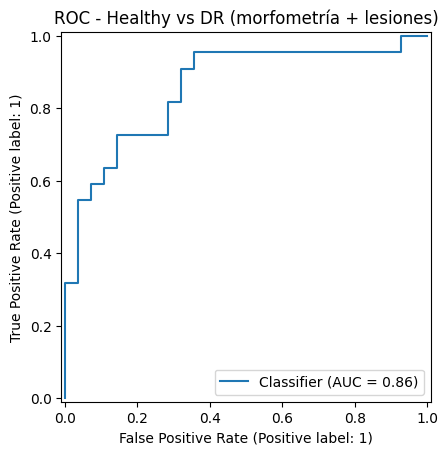

,Modelo,Accuracy,F1_macro,MAE,QWK,ROC-AUC
0,XGBoost Multiclase,0.62,0.263704,0.74,0.441592,NaN
1,LogisticAT Ordinal,0.56,0.297094,0.72,0.480519,NaN
2,XGBoost Binario,0.80,0.794745,0.20,NaN,0.857143


In [41]:
# ==========================================
# ENTRENAR 3 MODELOS + TABLA COMPARATIVA
# ==========================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    cohen_kappa_score,
    mean_absolute_error,
    roc_auc_score,
    RocCurveDisplay,
    f1_score,
    accuracy_score
)

from xgboost import XGBClassifier
import mord

# ------------------------------------------------------------------
# 0) Preparar datos base
# ------------------------------------------------------------------
df_model = full_df.copy()
df_model["diagnosis"] = df_model["diagnosis"].astype(int)
df_model["endpoint_bif_ratio"] = df_model["endpoint_bif_ratio"].fillna(0)

# Asegurate de tener definida feature_cols antes de esta celda
# feature_cols = [...]

results = []

# ------------------------------------------------------------------
# 1) XGBoost MULTICLASE (0–4)
# ------------------------------------------------------------------
X_mc = df_model[feature_cols].values
y_mc = df_model["diagnosis"].values  # 0–4

X_train_mc, X_test_mc, y_train_mc, y_test_mc = train_test_split(
    X_mc, y_mc,
    test_size=0.25,
    random_state=42,
    stratify=y_mc
)

pipe_xgb_multi = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", XGBClassifier(
        n_estimators=400,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.9,
        colsample_bytree=0.9,
        objective="multi:softprob",
        num_class=5,
        eval_metric="mlogloss"
    ))
])

pipe_xgb_multi.fit(X_train_mc, y_train_mc)
y_pred_multi = pipe_xgb_multi.predict(X_test_mc)

print("===== XGBOOST MULTICLASS (0–4) =====")
print(classification_report(y_test_mc, y_pred_multi))
print("Confusion matrix:")
print(confusion_matrix(y_test_mc, y_pred_multi))

qwk_multi = cohen_kappa_score(y_test_mc, y_pred_multi, weights="quadratic")
mae_multi = mean_absolute_error(y_test_mc, y_pred_multi)
print(f"Quadratic Weighted Kappa: {qwk_multi:.3f}")
print(f"MAE: {mae_multi:.3f}")
print("\n")

# ------------------------------------------------------------------
# 2) MODELO ORDINAL (LogisticAT, mord)
#    Usamos el MISMO split que el multiclase para comparar justo
# ------------------------------------------------------------------
pipe_ordinal = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", mord.LogisticAT(alpha=1.0))
])

pipe_ordinal.fit(X_train_mc, y_train_mc)
y_pred_ord = pipe_ordinal.predict(X_test_mc)

print("===== MODELO ORDINAL (LogisticAT) =====")
print(classification_report(y_test_mc, y_pred_ord))
print("Confusion matrix:")
print(confusion_matrix(y_test_mc, y_pred_ord))

qwk_ord = cohen_kappa_score(y_test_mc, y_pred_ord, weights="quadratic")
mae_ord = mean_absolute_error(y_test_mc, y_pred_ord)
print(f"Quadratic Weighted Kappa: {qwk_ord:.3f}")
print(f"MAE: {mae_ord:.3f}")
print("\n")

# ------------------------------------------------------------------
# 3) XGBoost BINARIO (0 vs DR)
# ------------------------------------------------------------------
X_bin = df_model[feature_cols].values
y_bin = (df_model["diagnosis"] > 0).astype(int).values   # 0 = sano, 1 = cualquier DR

print("Proporción de DR:", y_bin.mean())

X_train_bin, X_test_bin, y_train_bin, y_test_bin = train_test_split(
    X_bin, y_bin,
    test_size=0.25,
    random_state=42,
    stratify=y_bin
)

# balance de clases
pos = (y_train_bin == 1).sum()
neg = (y_train_bin == 0).sum()
scale_pos_weight = neg / max(pos, 1)

pipe_xgb_bin = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", XGBClassifier(
        n_estimators=400,
        max_depth=4,
        learning_rate=0.05,
        subsample=0.9,
        colsample_bytree=0.9,
        objective="binary:logistic",
        eval_metric="logloss",
        scale_pos_weight=scale_pos_weight
    ))
])

pipe_xgb_bin.fit(X_train_bin, y_train_bin)

y_proba_bin = pipe_xgb_bin.predict_proba(X_test_bin)[:, 1]
y_pred_bin = (y_proba_bin >= 0.5).astype(int)

print("===== XGBOOST BINARIO (0 vs DR) =====")
print(classification_report(y_test_bin, y_pred_bin))
print("Confusion matrix:")
print(confusion_matrix(y_test_bin, y_pred_bin))

roc_auc = roc_auc_score(y_test_bin, y_proba_bin)
print(f"ROC-AUC: {roc_auc:.3f}")

RocCurveDisplay.from_predictions(y_test_bin, y_proba_bin)
plt.title("ROC - Healthy vs DR (morfometría + lesiones)")
plt.show()
print("\n")

# ------------------------------------------------------------------
# 4) Función para recolectar métricas + tabla resumen
# ------------------------------------------------------------------
def collect_metrics(model_name, y_test, y_pred, y_proba=None, binary=False):
    row = {
        "Modelo": model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "F1_macro": f1_score(y_test, y_pred, average="macro"),
        "MAE": mean_absolute_error(y_test, y_pred),
    }

    # QWK solo tiene sentido en ordinal/multiclase
    if not binary:
        row["QWK"] = cohen_kappa_score(y_test, y_pred, weights="quadratic")
    else:
        row["QWK"] = None

    # ROC-AUC solo en binario
    if binary and y_proba is not None:
        row["ROC-AUC"] = roc_auc_score(y_test, y_proba)
    else:
        row["ROC-AUC"] = None

    return row

results = []

# MULTICLASS
results.append(collect_metrics(
    model_name="XGBoost Multiclase",
    y_test=y_test_mc,
    y_pred=y_pred_multi,
    y_proba=None,
    binary=False
))

# ORDINAL
results.append(collect_metrics(
    model_name="LogisticAT Ordinal",
    y_test=y_test_mc,
    y_pred=y_pred_ord,
    y_proba=None,
    binary=False
))

# BINARIO
results.append(collect_metrics(
    model_name="XGBoost Binario",
    y_test=y_test_bin,
    y_pred=y_pred_bin,
    y_proba=y_proba_bin,
    binary=True
))

summary_df = pd.DataFrame(results)
summary_df

In [ ]:
# ==========================================
# FEATURE IMPORTANCE + SHAP (MULTI y BINARIO)
# ==========================================
!pip install shap -q

import shap
import matplotlib.pyplot as plt
import numpy as np

# ------------------------------
# 1) Recuperar modelos y scalers
# (definidos en la celda anterior)
# ------------------------------
xgb_multi = pipe_xgb_multi.named_steps["clf"]
scaler_multi = pipe_xgb_multi.named_steps["scaler"]

xgb_bin = pipe_xgb_bin.named_steps["clf"]
scaler_bin = pipe_xgb_bin.named_steps["scaler"]

# Escalar X_train (mismas features que vio el modelo)
X_train_mc_scaled = scaler_multi.transform(X_train_mc)
X_train_bin_scaled = scaler_bin.transform(X_train_bin)

# ==============================
# 2) FEATURE IMPORTANCE
# ==============================

# --- Multiclase ---
importances_multi = xgb_multi.feature_importances_

plt.figure(figsize=(8, 6))
plt.barh(feature_cols, importances_multi)
plt.title("XGBoost Multiclase - Feature Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

# --- Binario ---
importances_bin = xgb_bin.feature_importances_

plt.figure(figsize=(8, 6))
plt.barh(feature_cols, importances_bin)
plt.title("XGBoost Binario (0 vs DR) - Feature Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

# ==============================
# 3) SHAP - XGBoost MULTICLASE
# ==============================

explainer_multi = shap.TreeExplainer(xgb_multi)
shap_values_multi = explainer_multi.shap_values(X_train_mc_scaled)

# shap_values_multi suele ser una lista [n_clases]
if isinstance(shap_values_multi, list):
    # elegimos la clase 4 (DR más severa)
    class_idx = 4
    shap_class = shap_values_multi[class_idx]
else:
    # caso raro: una sola matriz (n_muestras, n_features) o (n_muestras, n_clases, n_features)
    shap_class = shap_values_multi

print("Shape SHAP multiclase:", shap_class.shape)
print("Shape X_train_mc_scaled:", X_train_mc_scaled.shape)

# Si hay una columna extra (bias), la sacamos
if shap_class.ndim == 2 and shap_class.shape[1] == X_train_mc_scaled.shape[1] + 1:
    shap_class = shap_class[:, :-1]

# Si tuviera otra forma rara, intentamos adaptar solo si coincide en n_features
assert shap_class.shape[1] == X_train_mc_scaled.shape[1], \
    "Aún no matchean las dimensiones de SHAP y X_train_mc_scaled."

print("SHAP summary para clase 4 (diagnosis=4)")
shap.summary_plot(
    shap_class,
    X_train_mc_scaled,
    feature_names=feature_cols,
    show=True
)

# ==============================
# 4) SHAP - XGBoost BINARIO
# ==============================

explainer_bin = shap.TreeExplainer(xgb_bin)
shap_values_bin = explainer_bin.shap_values(X_train_bin_scaled)

# En binario normalmente shap_values_bin tiene shape (n_samples, n_features)
shap_bin = shap_values_bin

print("Shape SHAP binario:", np.array(shap_bin).shape)
print("Shape X_train_bin_scaled:", X_train_bin_scaled.shape)

# Si viene con columna extra de bias
if np.array(shap_bin).ndim == 2 and shap_bin.shape[1] == X_train_bin_scaled.shape[1] + 1:
    shap_bin = shap_bin[:, :-1]

assert shap_bin.shape[1] == X_train_bin_scaled.shape[1], \
    "Aún no matchean las dimensiones de SHAP y X_train_bin_scaled."

print("SHAP summary para modelo binario (probabilidad de DR)")
shap.summary_plot(
    shap_bin,
    X_train_bin_scaled,
    feature_names=feature_cols,
    show=True
)


In [ ]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import shap
import numpy as np
import pandas as pd

# Si no lo hiciste antes:
# explainer_bin = shap.TreeExplainer(pipe_xgb_bin.named_steps["clf"])

def visualize_case_with_shap(idx=0, csv_path=CSV_PATH):
    """
    Visualiza:
      - Imagen original
      - Máscara de vasos
      - Overlay
      - SHAP values del modelo binario (0 vs DR) para esa imagen

    idx: índice de la fila en df_model/full_df que querés visualizar.
    csv_path: ruta al CSV original con la columna 'resolved_name'.
    """
    # --- 1) Seleccionar caso en el DF de features ---
    row_feat = full_df.iloc[idx]
    img_name = row_feat["image"]
    diagnosis = int(row_feat["diagnosis"])

    # --- 2) Buscar la fila correspondiente en el CSV original ---
    df_csv = pd.read_csv(csv_path)
    row_img = df_csv[df_csv["resolved_name"] == img_name].iloc[0]

    # --- 3) Cargar y procesar imagen ---
    img = load_image_from_row(row_img)                 # RGB original
    vessel_mask, _, img_pre = segment_vessels_fcu(img, use_preprocess=True)

    overlay = img_pre.copy()
    overlay[vessel_mask == 1] = [255, 0, 0]

    # --- 4) SHAP del modelo binario para este caso ---
    xgb_bin = pipe_xgb_bin.named_steps["clf"]
    scaler_bin = pipe_xgb_bin.named_steps["scaler"]

    x_sample = row_feat[feature_cols].values.reshape(1, -1)
    x_sample_scaled = scaler_bin.transform(x_sample)

    explainer_bin = shap.TreeExplainer(xgb_bin)
    shap_values = explainer_bin.shap_values(x_sample_scaled)  # (1, n_features)
    shap_values = np.array(shap_values).reshape(-1)            # (n_features,)

    # --- 5) Figura con 2 filas (3 cols arriba, 1 abajo) ---
    fig = plt.figure(figsize=(14, 8))
    gs = gridspec.GridSpec(2, 3, height_ratios=[2, 1])

    ax1 = fig.add_subplot(gs[0, 0])
    ax2 = fig.add_subplot(gs[0, 1])
    ax3 = fig.add_subplot(gs[0, 2])
    ax4 = fig.add_subplot(gs[1, :])  # fila 2 completa

    # Fila 1: imágenes
    ax1.imshow(img)
    ax1.set_title(f"Original (Diagnostic={diagnosis})")
    ax1.axis("off")

    ax2.imshow(vessel_mask, cmap="gray")
    ax2.set_title("Vessel Mask")
    ax2.axis("off")

    ax3.imshow(overlay)
    ax3.set_title("Overlay")
    ax3.axis("off")

    # Fila 2: SHAP del modelo binario (barh)
    # Ordenamos por |shap|
    order = np.argsort(np.abs(shap_values))[::-1]
    shap_sorted = shap_values[order]
    feat_sorted = [feature_cols[i] for i in order]

    colors = ["tab:red" if v > 0 else "tab:blue" for v in shap_sorted]

    ax4.barh(feat_sorted, shap_sorted, color=colors)
    ax4.axvline(0, color="k", linewidth=1)
    ax4.set_title("SHAP (binary model 0 vs DR)")
    ax4.set_xlabel("SHAP value")

    plt.tight_layout()
    plt.show()


# Ejemplo de uso: visualizar el primer caso
visualize_case_with_shap(idx=0)


In [ ]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import shap
import numpy as np
import pandas as pd

def visualize_case_with_shap(idx=0, csv_path=CSV_PATH, top_k=None):
    """
    Visualiza:
      - Fila 1: imagen original, máscara de vasos, overlay
      - Fila 2: scatter tipo SHAP del modelo binario (0 vs DR) para ese paciente

    idx: índice en full_df del caso a mostrar
    top_k: si no es None, muestra solo las top_k features por |SHAP|
    """

    # --- 1) Seleccionar caso de full_df ---
    row_feat = full_df.iloc[idx]
    img_name = row_feat["image"]
    diagnosis = int(row_feat["diagnosis"])

    # --- 2) Buscar la fila correspondiente en el CSV original ---
    df_csv = pd.read_csv(csv_path)
    row_img = df_csv[df_csv["resolved_name"] == img_name].iloc[0]

    # --- 3) Cargar imagen y segmentar vasos ---
    img = load_image_from_row(row_img)
    vessel_mask, _, img_pre = segment_vessels_fcu(img, use_preprocess=True)

    overlay = img_pre.copy()
    overlay[vessel_mask == 1] = [255, 0, 0]

    # --- 4) SHAP para este caso (modelo binario) ---
    xgb_bin = pipe_xgb_bin.named_steps["clf"]
    scaler_bin = pipe_xgb_bin.named_steps["scaler"]

    x_sample = row_feat[feature_cols].values.reshape(1, -1)
    x_sample_scaled = scaler_bin.transform(x_sample)

    explainer_bin = shap.TreeExplainer(xgb_bin)
    shap_values = explainer_bin.shap_values(x_sample_scaled)  # (1, n_features)
    shap_values = np.array(shap_values).reshape(-1)           # (n_features,)

    # Valores de feature para colorear (uso los originales, no escalados)
    feat_vals = row_feat[feature_cols].values.astype(float)

    # Ordenar por |SHAP|
    order = np.argsort(np.abs(shap_values))[::-1]
    if top_k is not None:
        order = order[:top_k]

    shap_sorted = shap_values[order]
    feat_sorted = [feature_cols[i] for i in order]
    vals_sorted = feat_vals[order]

    # Normalizar valores para mapa de color
    vmin, vmax = vals_sorted.min(), vals_sorted.max()
    if vmax == vmin:
        vmax = vmin + 1e-6
    norm = plt.Normalize(vmin=vmin, vmax=vmax)
    cmap = plt.cm.coolwarm
    colors = cmap(norm(vals_sorted))

    # --- 5) Figura con 2 filas: 3 columnas arriba, 1 abajo ---
    fig = plt.figure(figsize=(14, 8))
    gs = gridspec.GridSpec(2, 3, height_ratios=[2, 1.5])

    ax1 = fig.add_subplot(gs[0, 0])
    ax2 = fig.add_subplot(gs[0, 1])
    ax3 = fig.add_subplot(gs[0, 2])
    ax4 = fig.add_subplot(gs[1, :])

    # Fila 1: imágenes
    ax1.imshow(img)
    ax1.set_title(f"Original (Diagnostic={diagnosis})")
    ax1.axis("off")

    ax2.imshow(vessel_mask, cmap="gray")
    ax2.set_title("Vessel Mask")
    ax2.axis("off")

    ax3.imshow(overlay)
    ax3.set_title("Overlay")
    ax3.axis("off")

    # Fila 2: scatter tipo SHAP
    y_pos = np.arange(len(feat_sorted))

    ax4.scatter(shap_sorted, y_pos, c=colors, s=50, edgecolors="k")
    ax4.axvline(0, color="k", linewidth=1)
    ax4.set_yticks(y_pos)
    ax4.set_yticklabels(feat_sorted)
    ax4.invert_yaxis()  # más importante arriba
    ax4.set_xlabel("SHAP value (impacto en probabilidad de DR)")
    ax4.set_title("SHAP (binary model 0 vs DR) para este paciente")

    ax4.grid(True, axis="x", linestyle="--", alpha=0.3)

    # Colorbar para valores de feature
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    cbar = fig.colorbar(sm, ax=ax4, orientation="vertical")
    cbar.set_label("Feature value (bajo → alto)")

    plt.tight_layout()
    plt.show()


# Ejemplo: solo top 8 features para que quede limpio
visualize_case_with_shap(idx=0, top_k=8)

#**Modelo #3**

In [ ]:
# =========================================================
# BINARIO (0 vs DR) — sin StandardScaler + threshold óptimo
# Objetivo: elegir umbral para Sensibilidad >= 0.90 (screening)
# Reporta: Sens, Spec, NPV, PPV, F1, Acc, ROC-AUC + curva ROC
# =========================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    confusion_matrix, classification_report,
    roc_auc_score, RocCurveDisplay,
    accuracy_score, f1_score
)
from xgboost import XGBClassifier

# --- 0) Datos ---
df_model = full_df.copy()
df_model["diagnosis"] = df_model["diagnosis"].astype(int)
df_model["endpoint_bif_ratio"] = df_model["endpoint_bif_ratio"].fillna(0)

X = df_model[feature_cols].values
y = (df_model["diagnosis"] > 0).astype(int).values  # 0=sano, 1=DR

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

# --- 1) Balance de clases (scale_pos_weight) ---
pos = (y_train == 1).sum()
neg = (y_train == 0).sum()
scale_pos_weight = neg / max(pos, 1)

# --- 2) Entrenar XGB binario SIN scaler ---
xgb_bin = XGBClassifier(
    n_estimators=400,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.9,
    colsample_bytree=0.9,
    objective="binary:logistic",
    eval_metric="logloss",
    scale_pos_weight=scale_pos_weight,
    random_state=42
)

xgb_bin.fit(X_train, y_train)

# --- 3) Probabilidades + AUC ---
y_proba = xgb_bin.predict_proba(X_test)[:, 1]
auc = roc_auc_score(y_test, y_proba)
print(f"ROC-AUC (binario, sin scaler): {auc:.4f}")

RocCurveDisplay.from_predictions(y_test, y_proba)
plt.title("ROC - Healthy vs DR (XGB sin scaler)")
plt.show()

# --- 4) Buscar umbral para Sensibilidad >= target_sens ---
def metrics_at_threshold(y_true, y_proba, thr):
    y_pred = (y_proba >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()

    sens = tp / (tp + fn) if (tp + fn) else 0.0              # recall positivo
    spec = tn / (tn + fp) if (tn + fp) else 0.0
    ppv  = tp / (tp + fp) if (tp + fp) else 0.0              # precision
    npv  = tn / (tn + fn) if (tn + fn) else 0.0
    acc  = (tp + tn) / (tp + tn + fp + fn) if (tp + tn + fp + fn) else 0.0
    f1   = f1_score(y_true, y_pred)

    return {
        "threshold": thr,
        "TP": tp, "FP": fp, "TN": tn, "FN": fn,
        "sensitivity": sens,
        "specificity": spec,
        "PPV": ppv,
        "NPV": npv,
        "accuracy": acc,
        "F1": f1
    }

target_sens = 0.90
thresholds = np.linspace(0.01, 0.99, 99)

rows = [metrics_at_threshold(y_test, y_proba, thr) for thr in thresholds]
thr_df = pd.DataFrame(rows)

# umbrales que cumplen sensibilidad objetivo
candidates = thr_df[thr_df["sensitivity"] >= target_sens].copy()

if len(candidates) == 0:
    print(f"No se encontró threshold con sensibilidad >= {target_sens:.2f}.")
    # fallback: el que maximiza sensibilidad (y luego especificidad)
    best = thr_df.sort_values(["sensitivity", "specificity"], ascending=False).iloc[0]
else:
    # elegimos el que MAXIMIZA especificidad manteniendo sensibilidad >= target
    best = candidates.sort_values(["specificity", "NPV", "F1"], ascending=False).iloc[0]

best_thr = float(best["threshold"])
print("\n===== Mejor threshold (screening) =====")
print(f"Target Sensitivity: {target_sens:.2f}")
print(f"Chosen threshold:   {best_thr:.2f}")
print(f"Sensitivity:        {best['sensitivity']:.3f}")
print(f"Specificity:        {best['specificity']:.3f}")
print(f"NPV:                {best['NPV']:.3f}")
print(f"PPV:                {best['PPV']:.3f}")
print(f"Accuracy:           {best['accuracy']:.3f}")
print(f"F1:                 {best['F1']:.3f}")

# --- 5) Reporte final con ese threshold ---
y_pred_best = (y_proba >= best_thr).astype(int)

print("\nConfusion matrix (best thr):")
print(confusion_matrix(y_test, y_pred_best))

print("\nClassification report (best thr):")
print(classification_report(y_test, y_pred_best, digits=3))

# --- 6) (Opcional) ver la tabla ordenada de thresholds ---
# Mostrar las top 10 por especificidad dentro del target de sensibilidad
if len(candidates) > 0:
    display(candidates.sort_values(["specificity", "NPV", "F1"], ascending=False).head(10))
else:
    display(thr_df.sort_values(["sensitivity", "specificity"], ascending=False).head(10))
